In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/processed/customer_features.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (4338, 9)


,CustomerID,TotalSpent,TotalOrders,TotalItems,AverageOrderValue,AverageUnitPrice,UniqueProducts,UniqueCountries,HighValueCustomer
0,12346,77183.60,1,74215,77183.600000,1.040000,1,1,1
1,12347,4310.00,7,2458,23.681319,2.644011,103,1,1
2,12348,1797.24,4,2341,57.975484,5.764839,22,1,1
3,12349,1757.55,1,631,24.076027,8.289041,73,1,1
4,12350,334.40,1,197,19.670588,3.841176,17,1,0


In [3]:
features = [
    "TotalOrders",
    "TotalItems",
    "AverageOrderValue",
    "AverageUnitPrice",
    "UniqueProducts",
    "UniqueCountries"
]

X = df[features]
y = df["HighValueCustomer"]

In [4]:
print("Features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Features:
['TotalOrders', 'TotalItems', 'AverageOrderValue', 'AverageUnitPrice', 'UniqueProducts', 'UniqueCountries']

Target distribution:
HighValueCustomer
0    3253
1    1085
Name: count, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 3470
Testing samples: 868


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

model.fit(X_train_scaled, y_train)

print("Model trained successfully!")

Model trained successfully!


In [8]:
y_pred = model.predict(X_test_scaled)

In [9]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.9240
Precision: 0.8832
Recall   : 0.8018
F1 Score : 0.8406


In [10]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.96      0.95       651
           1       0.88      0.80      0.84       217

    accuracy                           0.92       868
   macro avg       0.91      0.88      0.90       868
weighted avg       0.92      0.92      0.92       868



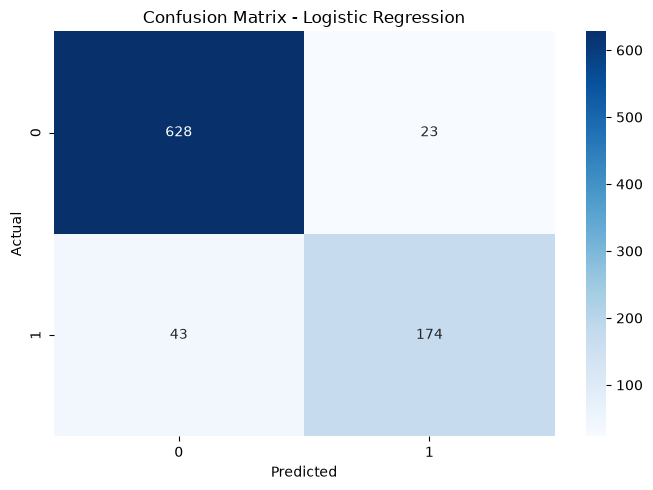

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    "../visualizations/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# ==============================
# DECISION TREE
# ==============================

decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

decision_tree.fit(X_train, y_train)

dt_pred = decision_tree.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred)
dt_recall = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

print("Decision Tree Results")
print("====================")
print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1 Score : {dt_f1:.4f}")


# ==============================
# RANDOM FOREST
# ==============================

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=8
)

random_forest.fit(X_train, y_train)

rf_pred = random_forest.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print("\nRandom Forest Results")
print("====================")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")

Decision Tree Results
Accuracy : 0.9505
Precision: 0.9028
Recall   : 0.8986
F1 Score : 0.9007

Random Forest Results
Accuracy : 0.9585
Precision: 0.9330
Recall   : 0.8986
F1 Score : 0.9155


In [13]:
# ==========================================
# MODEL COMPARISON
# ==========================================

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        dt_accuracy,
        rf_accuracy
    ],
    "Precision": [
        precision,
        dt_precision,
        rf_precision
    ],
    "Recall": [
        recall,
        dt_recall,
        rf_recall
    ],
    "F1 Score": [
        f1,
        dt_f1,
        rf_f1
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.923963,0.883249,0.801843,0.840580
1,Decision Tree,0.950461,0.902778,0.898618,0.900693
2,Random Forest,0.958525,0.933014,0.898618,0.915493


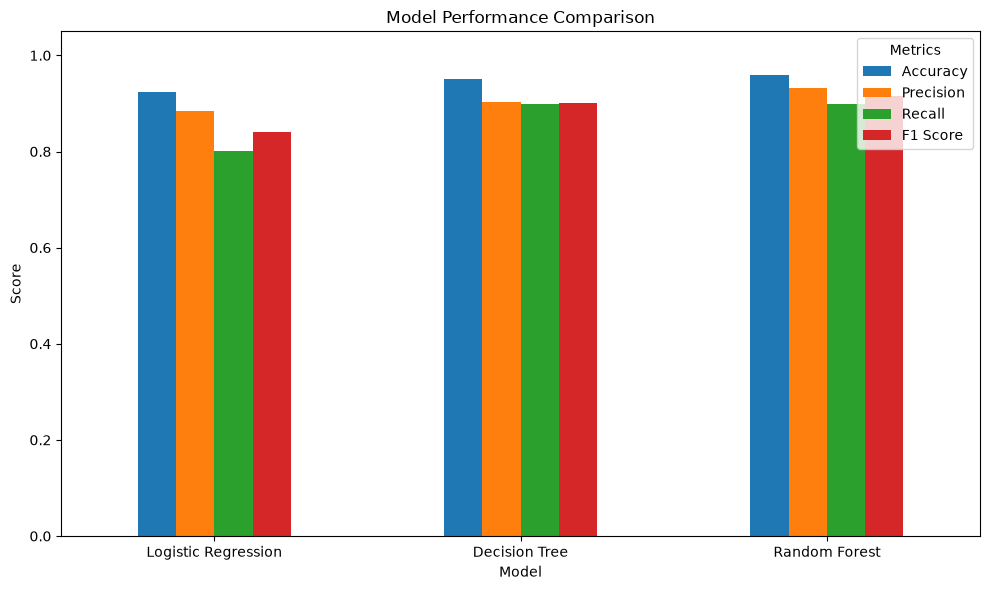

In [14]:
# ==========================================
# MODEL PERFORMANCE COMPARISON
# ==========================================

comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()

plt.savefig(
    "../visualizations/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# ==========================================
# RANDOM FOREST FEATURE IMPORTANCE
# ==========================================

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": random_forest.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
             Feature  Importance
1         TotalItems    0.479023
0        TotalOrders    0.208248
4     UniqueProducts    0.165115
2  AverageOrderValue    0.092030
3   AverageUnitPrice    0.055156
5    UniqueCountries    0.000428


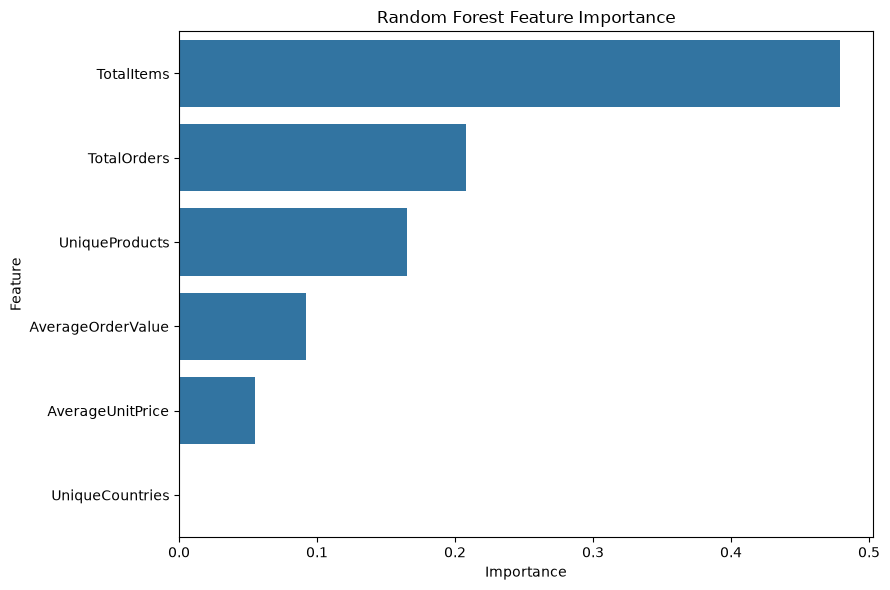

In [16]:
# ==========================================
# FEATURE IMPORTANCE VISUALIZATION
# ==========================================

plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    "../visualizations/random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
import joblib

# Save the model
joblib.dump(
    random_forest,
    "../models/retail_model.pkl"
)

# Save the scaler too
joblib.dump(
    scaler,
    "../models/scaler.pkl"
)

print("Random Forest model saved successfully!")
print("Scaler saved successfully!")

Random Forest model saved successfully!
Scaler saved successfully!


In [18]:
# ==========================================
# TEST SAVED MODEL
# ==========================================

import joblib
import pandas as pd

# Load saved model and scaler
loaded_model = joblib.load("../models/retail_model.pkl")
loaded_scaler = joblib.load("../models/scaler.pkl")

print("Model and scaler loaded successfully!")

Model and scaler loaded successfully!


In [19]:
# Take one customer from the test set
sample_customer = X_test.iloc[[0]]

# Scale the customer data
sample_scaled = loaded_scaler.transform(sample_customer)

# Make prediction
prediction = loaded_model.predict(sample_scaled)[0]

print("Customer features:")
print(sample_customer)

print("\nPrediction:")

if prediction == 1:
    print("High-Value Customer")
else:
    print("Regular Customer")

Customer features:
     TotalOrders  TotalItems  AverageOrderValue  AverageUnitPrice  \
937            1         267          18.647391           2.06087   

     UniqueProducts  UniqueCountries  
937              23                1  

Prediction:
Regular Customer


e:\OnlineRetail_project\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [20]:
# ==========================================
# TEST MULTIPLE CUSTOMERS
# ==========================================

sample_customers = X_test.iloc[:10]

sample_scaled = loaded_scaler.transform(sample_customers)

predictions = loaded_model.predict(sample_scaled)

results = sample_customers.copy()
results["PredictedClass"] = predictions
results["PredictedCustomerType"] = results["PredictedClass"].map({
    0: "Regular Customer",
    1: "High-Value Customer"
})

results

e:\OnlineRetail_project\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


,TotalOrders,TotalItems,AverageOrderValue,AverageUnitPrice,UniqueProducts,UniqueCountries,PredictedClass,PredictedCustomerType
937,1,267,18.647391,2.060870,23,1,0,Regular Customer
209,2,201,15.886250,2.591250,15,1,0,Regular Customer
2307,6,1646,20.130455,3.895390,108,1,0,Regular Customer
1346,3,1515,21.626174,3.706376,139,1,0,Regular Customer
2459,1,72,68.400000,1.900000,2,1,0,Regular Customer
1159,2,474,13.743214,2.836071,24,1,0,Regular Customer
1090,2,153,6.536271,3.291695,51,1,0,Regular Customer
1080,1,29,12.920833,7.108333,11,1,0,Regular Customer
3595,1,36,2.758261,2.011304,23,1,0,Regular Customer
1783,11,3134,21.694872,0.985812,44,1,0,Regular Customer


In [21]:
from sklearn.metrics import roc_curve, roc_auc_score

# Get prediction probabilities
y_probability = loaded_model.predict_proba(X_test)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_probability)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_probability)

print(f"ROC-AUC Score: {auc_score:.4f}")

ROC-AUC Score: 0.9924


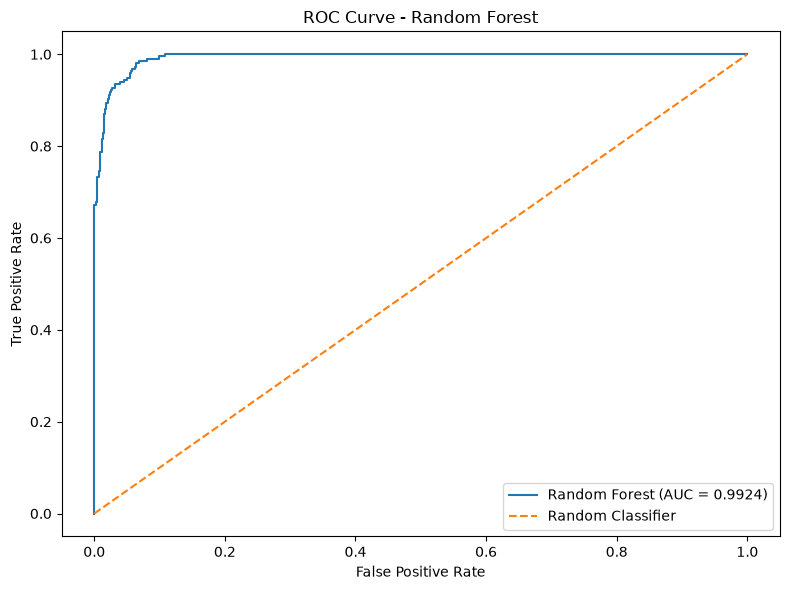

In [22]:
# ==========================================
# ROC CURVE
# ==========================================

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {auc_score:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.tight_layout()

plt.savefig(
    "../visualizations/roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Machine Learning Conclusion

The project developed a classification model to identify high-value customers
using their purchasing behavior.

Three machine learning algorithms were evaluated:

- Logistic Regression
- Decision Tree
- Random Forest

The models were evaluated using:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC

Random Forest feature importance showed that `TotalItems`, `TotalOrders`,
and `UniqueProducts` were the most influential features in the model.

The trained Random Forest model was saved as:

`models/retail_model.pkl`

The scaler used during preprocessing was saved as:

`models/scaler.pkl`

The ROC curve and model evaluation visualizations were also saved in the
`visualizations/` directory.

This completes the data cleaning, exploratory analysis, feature engineering,
machine learning, evaluation, and model-saving stages of the project.